In [15]:
from scipy.stats import binom
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Биномиальное распределение

In [16]:
binom_h0 = binom(n = 30, p = 0.5)

Функция вероятности дискретного распределения — вероятность, с которой СВ принимает определенное значение.
PMF (probability mass function)

In [17]:
binom_h0.pmf(15)

np.float64(0.14446444809436781)

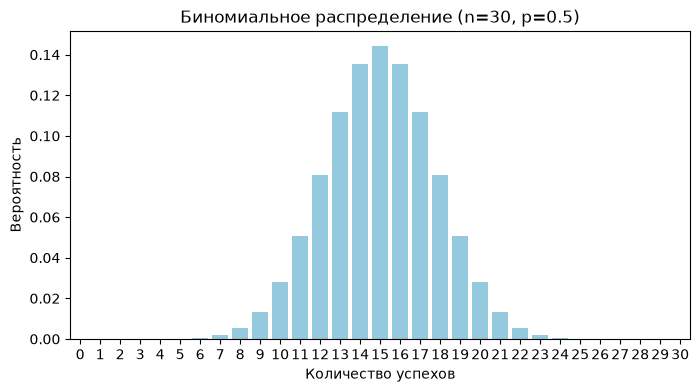

In [21]:
# Возможные значения случайной величины
x = np.arange(0, 31)

# Вероятности для каждого значения
y = binom_h0.pmf(x)

# Строим график
plt.figure(figsize=(8, 4))
sns.barplot(x=x, y=y, color='skyblue')

plt.xlabel('Количество успехов')
plt.ylabel('Вероятность')
plt.title('Биномиальное распределение (n=30, p=0.5)')
plt.show()

## Кумулятивная функция распределения (CDF)

Вероятность того, что СВ примет значение <= x

In [19]:
binom_h0.cdf(19)

np.float64(0.9506314266473055)

In [20]:
1 - binom_h0.cdf(19)

np.float64(0.04936857335269451)

## Квантиль (PPF)

In [ ]:
Значение, ниже или на уровне которого находится x% всего набора данных.

In [22]:
binom_h0.ppf(0.95)

np.float64(19.0)

## Построение критерия

In [23]:
def make_binom_criterion(n, mu=0.5, alpha=0.05):
    '''Строит критерий для задачи с доставкой
    
    Параметры:
        n: количество доставок в эксперименте
        mu: вероятность успеха в нулевой гипотезе
        alpha: уровень значимости критерия
        
    Возвращает:
        C для критерия S = {Q >= C}
    '''
    binom_h0 = binom(n=n, p=mu)
    q = binom_h0.ppf(1 - alpha)
    return q + 1

In [24]:
print(f'if Q >=', make_binom_criterion(
    n=30,
    mu=0.5,
    alpha=0.05
), 'then reject H0')

if Q >= 20.0 then reject H0


График распределения с отмеченным критическим значением

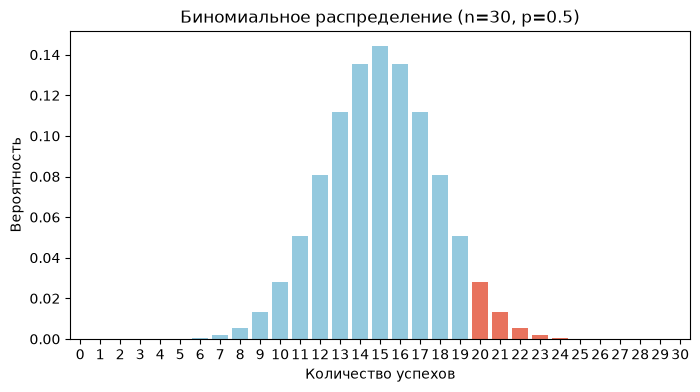

In [27]:
# Возможные значения случайной величины
x = np.arange(0, 31)

# Вероятности для каждого значения
y = binom_h0.pmf(x)

# Критическое значение
C = make_binom_criterion(n=30, mu=0.5, alpha=0.05)

# Цвета столбцов: голубой — обычная область, красный — критическая
colors = ['tomato' if i >= C else 'skyblue' for i in x]

# Строим график
plt.figure(figsize=(8, 4))
sns.barplot(x=x, y=y, palette=colors, hue=x, legend=False)

plt.xlabel('Количество успехов')
plt.ylabel('Вероятность')
plt.title('Биномиальное распределение (n=30, p=0.5)')
plt.show()
